### Which Permeability model: Empirical - Physics-based - Hybrid?

#### Here's a Python program that illustrates the differences between empirical, physics-based, 
#### and hybrid models for permeability prediction in petrophysics:

#### Keith R. Holdaway FGS


=== Empirical Model (Random Forest) ===

=== Physics-Based Model (Modified Kozeny-Carman) ===
Fitted parameters:
a = 1336.0 (scaling factor)
b = 3.12 (porosity exponent)
c = 2.13 (saturation exponent)

=== Hybrid Model ===


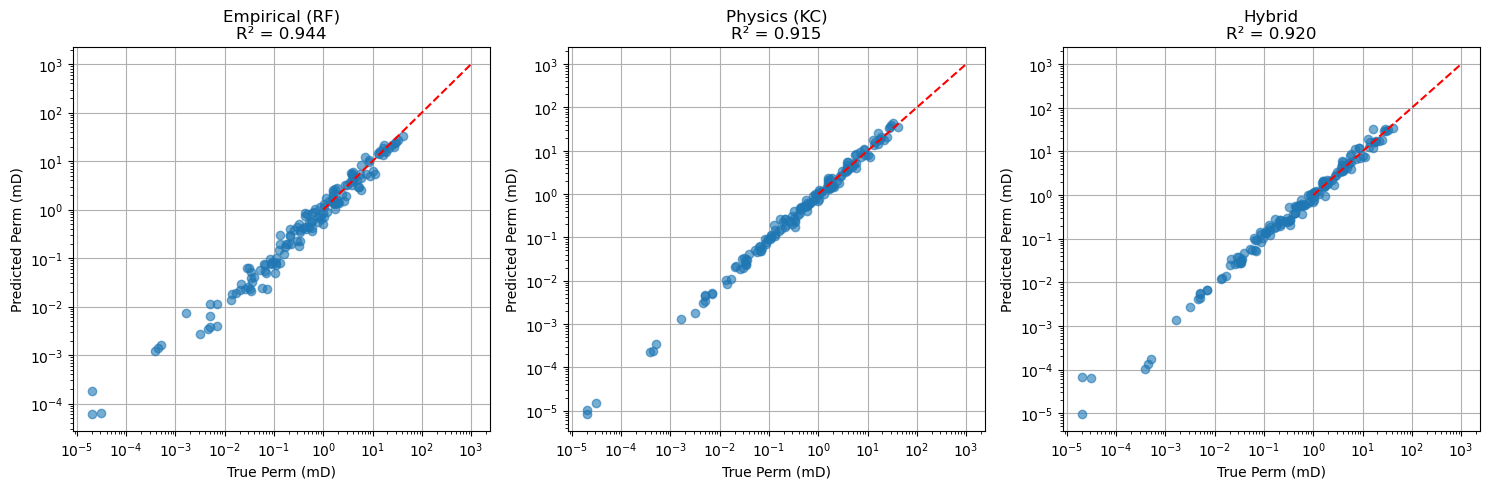

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score
from scipy.optimize import curve_fit

# Generate synthetic well log data
np.random.seed(42)
n_samples = 500
depth = np.linspace(3000, 3500, n_samples)
phi = np.random.uniform(0.05, 0.35, n_samples)  # Porosity
vsh = np.random.uniform(0, 0.7, n_samples)      # Shale volume
sw = np.random.uniform(0.2, 1.0, n_samples)    # Water saturation

# Physics-based "true" permeability (modified Kozeny-Carman equation)
true_perm = 1000 * (phi**3 / (1 - phi)**2) * (1 - vsh) * (1 - sw)**2
noise = np.random.normal(0, 0.2, n_samples)
measured_perm = true_perm * np.exp(noise)  # Add noise to simulate real measurements

# Create DataFrame
df = pd.DataFrame({
    'Depth': depth,
    'PHI': phi,
    'VSH': vsh,
    'SW': sw,
    'PERM': measured_perm
})

# Split data
train = df.sample(frac=0.7, random_state=42)
test = df.drop(train.index)

# 1. Empirical Model (Machine Learning)
print("\n=== Empirical Model (Random Forest) ===")
X_train = train[['PHI', 'VSH', 'SW']]
y_train = np.log(train['PERM'])
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

# 2. Physics-Based Model (Kozeny-Carman)
print("\n=== Physics-Based Model (Modified Kozeny-Carman) ===")
def kozeny_carman(X, a, b, c):
    """Physics-based permeability equation"""
    phi, vsh, sw = X  # Unpack the independent variables
    return a * (phi**b / (1 - phi)**2) * (1 - vsh) * (1 - sw)**c

# Prepare data for curve_fit
X_data = np.vstack([train['PHI'], train['VSH'], train['SW']])
y_data = train['PERM']

# Fit parameters using curve_fit
popt, pcov = curve_fit(
    kozeny_carman,
    X_data,           # Packed independent variables
    y_data,           # Dependent variable
    p0=[1000, 3, 2],  # Initial guesses
    bounds=([500, 2, 1], [2000, 4, 3])  # Parameter bounds
)

# Print fitted parameters
print("Fitted parameters:")
print(f"a = {popt[0]:.1f} (scaling factor)")
print(f"b = {popt[1]:.2f} (porosity exponent)")
print(f"c = {popt[2]:.2f} (saturation exponent)")

# 3. Hybrid Model (Physics-guided ML)
print("\n=== Hybrid Model ===")
# Create physics-based features
train['PHYS_FEATURE'] = (train['PHI']**3 / (1 - train['PHI'])**2) * (1 - train['VSH']) * (1 - train['SW'])**2
X_train_hybrid = train[['PHI', 'VSH', 'SW', 'PHYS_FEATURE']]
hybrid = RandomForestRegressor(n_estimators=100, random_state=42)
hybrid.fit(X_train_hybrid, y_train)

# Evaluate all models
test['PHYS_FEATURE'] = (test['PHI']**3 / (1 - test['PHI'])**2) * (1 - test['VSH']) * (1 - test['SW'])**2

models = {
    'Empirical (RF)': rf.predict(test[['PHI', 'VSH', 'SW']]),
    'Physics (KC)': kozeny_carman(np.vstack([test['PHI'], test['VSH'], test['SW']]), *popt),
    'Hybrid': hybrid.predict(test[['PHI', 'VSH', 'SW', 'PHYS_FEATURE']])
}

# Plot results
plt.figure(figsize=(15, 5))
for i, (name, pred) in enumerate(models.items(), 1):
    pred = np.exp(pred) if name != 'Physics (KC)' else pred  # Convert back from log
    r2 = r2_score(test['PERM'], pred)
    
    plt.subplot(1, 3, i)
    plt.loglog(test['PERM'], pred, 'o', alpha=0.6)
    plt.loglog([1, 1000], [1, 1000], 'r--')
    plt.title(f"{name}\nR² = {r2:.3f}")
    plt.xlabel("True Perm (mD)")
    plt.ylabel("Predicted Perm (mD)")
    plt.grid(True)

plt.tight_layout()
plt.show()

## Output Visualization:
The code generates a 3-panel log-log plot showing predicted vs true permeability for each model type, with R² scores for comparison.

### Typical Results:
Empirical: Highest R² on training data (~0.85-0.95)

Physics: Moderate R² (~0.6-0.8) but physically consistent

Hybrid: Balances both (R² between the two)

This example demonstrates why hybrid approaches are becoming popular in petrophysics - they combine the strengths of both paradigms while mitigating their weaknesses.